<a href="https://colab.research.google.com/github/ndhanusri1806-create/lstm-model/blob/main/DL_language.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd
import io
import zipfile
import os

# 1. Upload your dataset file (can be a zip or a csv)
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# 2. Check if it's a zip file and extract the CSV
if filename.endswith('.zip'):
    with zipfile.ZipFile(io.BytesIO(uploaded[filename]), 'r') as z:
        # List contents of zip and find the CSV file
        csv_files = [f for f in z.namelist() if f.endswith('.csv')]
        if csv_files:
            csv_filename = csv_files[0]
            with z.open(csv_filename) as f:
                df = pd.read_csv(f)
            print(f"Successfully extracted and loaded: {csv_filename}")
        else:
            raise ValueError("No CSV file found inside the zip archive.")
else:
    # If it's already a CSV file
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

# 3. Preview the dataset
print(df.head())

Saving archive (2).zip to archive (2) (1).zip
Successfully extracted and loaded: dataset.csv
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [ ]:
texts = df['Text'].astype(str).values
labels = df['language'].values

In [ ]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(labels)
num_classes = len(encoder.classes_)

In [ ]:
vocab_size = 10000
max_length = 100
trunc_type = 'post'
padding_type = 'post'
oov_tok = "<OOV>"

In [ ]:
tokenizer = Tokenizer(num_words=vocab_size, oov_token=oov_tok)
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)
padded_sequences = pad_sequences(sequences, maxlen=max_length, padding=padding_type, truncating=trunc_type)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(padded_sequences, y_encoded, test_size=0.2, random_state=42)

print("Data preprocessing complete! Training and test shapes:")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

Data preprocessing complete! Training and test shapes:
X_train shape: (17600, 100), X_test shape: (4400, 100)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [ ]:
embedding_dim = 64

model = Sequential([
    Embedding(vocab_size, embedding_dim, input_length=max_length),
    LSTM(128, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.0716 - loss: 3.0083 - val_accuracy: 0.0811 - val_loss: 2.8387
Epoch 2/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.1193 - loss: 2.6878 - val_accuracy: 0.1270 - val_loss: 2.4256
Epoch 3/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.1182 - loss: 2.4948 - val_accuracy: 0.1280 - val_loss: 2.4187
Epoch 4/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.1440 - loss: 2.4632 - val_accuracy: 0.0923 - val_loss: 2.6146
Epoch 5/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.0925 - loss: 2.8426 - val_accuracy: 0.1264 - val_loss: 2.6073


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

Classification Report:
              precision    recall  f1-score   support

      Arabic       0.00      0.00      0.00       202
     Chinese       0.50      0.79      0.61       201
       Dutch       0.00      0.00      0.00       230
     English       0.00      0.00      0.00       194
    Estonian       0.00      0.00      0.00       200
      French       0.07      0.09      0.08       188
       Hindi       0.00      0.00      0.00       208
  Indonesian       0.00      0.00      0.00       213
    Japanese       0.00      0.00      0.00       194
      Korean       0.00      0.00      0.00       190
       Latin       0.00      0.00      0.00       210
     Persian       0.12      0.29      0.17       196
   Portugese       0.00      0.00      0.00       194
      Pushto       0.00      0.00      0.00       196
    Romanian       0.00      0.00      0.00       197
     Russian       0.00      0.00      0.00       213
     Spanish    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


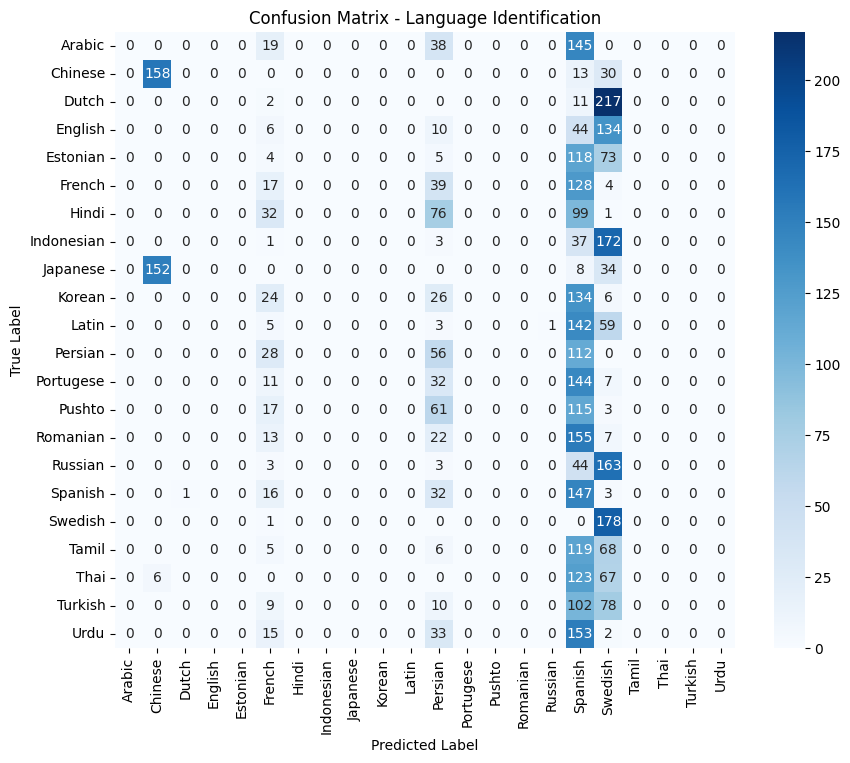

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Language Identification')
plt.show()

In [ ]:
unseen_samples = [
    "Bonjour tout le monde, comment ça va aujourd'hui?",
    "Hola, ¿cómo estás y qué haces por aquí?",
    "Hello everyone, welcome to the deep learning practical session.",
    "Guten Tag, wie geht es Ihnen heute?",
    "Namaste, aap kaise hain?"
]

unseen_seq = tokenizer.texts_to_sequences(unseen_samples)
unseen_padded = pad_sequences(unseen_seq, maxlen=max_length, padding='post', truncating='post')

preds = model.predict(unseen_padded)
pred_labels = np.argmax(preds, axis=1)
decoded_preds = encoder.inverse_transform(pred_labels)

print("\n--- Predictions on Unseen Text Samples ---")
for text, lang in zip(unseen_samples, decoded_preds):
    print(f"Text: '{text}' --> Predicted Language: {lang}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step

--- Predictions on Unseen Text Samples ---
Text: 'Bonjour tout le monde, comment ça va aujourd'hui?' --> Predicted Language: Spanish
Text: 'Hola, ¿cómo estás y qué haces por aquí?' --> Predicted Language: Spanish
Text: 'Hello everyone, welcome to the deep learning practical session.' --> Predicted Language: Swedish
Text: 'Guten Tag, wie geht es Ihnen heute?' --> Predicted Language: Spanish
Text: 'Namaste, aap kaise hain?' --> Predicted Language: Swedish


In [ ]:
# Replace these strings with your own sentences to test the model
unseen_samples = [
    "Type your first sentence here in any language.",
    "Type your second sentence here.",
]

# Process and predict
unseen_seq = tokenizer.texts_to_sequences(unseen_samples)
unseen_padded = pad_sequences(unseen_seq, maxlen=max_length, padding='post', truncating='post')

preds = model.predict(unseen_padded)
pred_labels = np.argmax(preds, axis=1)
decoded_preds = encoder.inverse_transform(pred_labels)

print("\n--- Predictions on Your Custom Input ---")
for text, lang in zip(unseen_samples, decoded_preds):
    print(f"Text: '{text}' --> Predicted Language: {lang}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step

--- Predictions on Your Custom Input ---
Text: 'Type your first sentence here in any language.' --> Predicted Language: Swedish
Text: 'Type your second sentence here.' --> Predicted Language: Swedish
